# Classification Part-A — Model Comparison

## 1. Consolidated Test-Set Comparison

In [1]:
from pathlib import Path
import sys
import joblib
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / 'data' / 'bank-full.csv').is_file():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError('Could not locate project root containing data/bank-full.csv')
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from classification_preprocessing import load_bank_dataset, prepare_features_target

RESULTS_DIR = PROJECT_ROOT / "results" / "classification"
MODELS_DIR = PROJECT_ROOT / "models" / "classification"
files = sorted(RESULTS_DIR.glob("*_classification.csv"))
if not files:
    raise FileNotFoundError("No classification result CSVs found. Run the five Classification Part-A notebooks first.")
comparison = pd.concat([pd.read_csv(p) for p in files], ignore_index=True)
comparison = comparison.sort_values("weighted_f1", ascending=False).reset_index(drop=True)
display(comparison)

,model,accuracy,precision,recall,weighted_f1,roc_auc
0,Decision Tree Classifier,0.901139,0.636667,0.361059,0.888863,0.852931
1,Logistic Regression,0.899149,0.634686,0.325142,0.884465,0.900583
2,K-Nearest Neighbors,0.898043,0.625461,0.320416,0.883198,0.834091
3,Support Vector Classifier (SVC),0.893177,0.650327,0.188091,0.866132,0.892569
4,Gaussian Naive Bayes,0.851930,0.394599,0.497164,0.859148,0.802065


## 2. Confusion Matrices

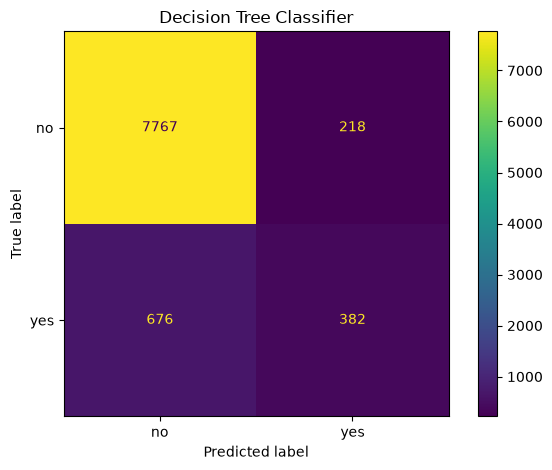

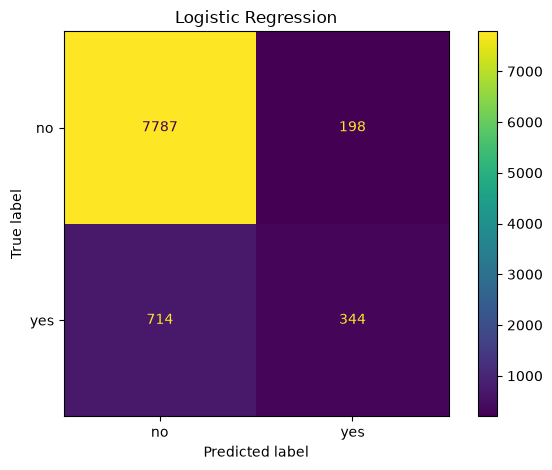

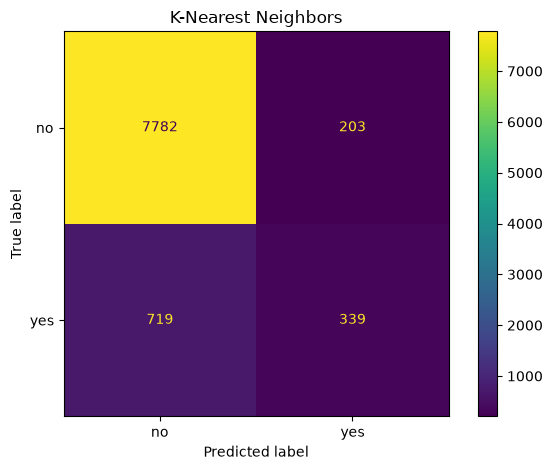

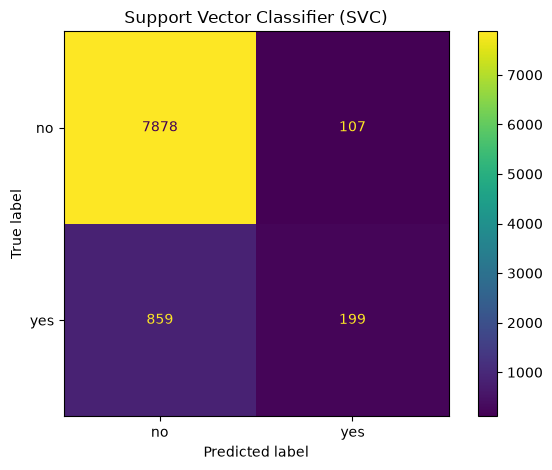

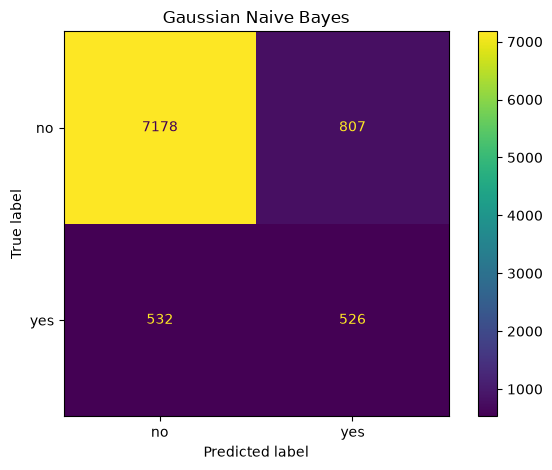

In [2]:
df = load_bank_dataset(PROJECT_ROOT / "data" / "bank-full.csv")
X, y = prepare_features_target(df)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

model_map = {
    "Logistic Regression": "01_logistic_regression_classification.joblib",
    "K-Nearest Neighbors": "02_knn_classifier_classification.joblib",
    "Gaussian Naive Bayes": "03_gaussian_naive_bayes_classification.joblib",
    "Decision Tree Classifier": "04_decision_tree_classifier_classification.joblib",
    "Support Vector Classifier (SVC)": "05_svc_classification.joblib"
}

for _, row in comparison.iterrows():
    model = joblib.load(MODELS_DIR / model_map[row["model"]])
    pred = model.predict(X_test)
    ConfusionMatrixDisplay(
        confusion_matrix(y_test, pred),
        display_labels=["no", "yes"]
    ).plot()
    plt.title(row["model"])
    plt.tight_layout()
    plt.show()